#### Multiclass Classification
:결과가 여러개의 클래슬 나오는 경우

## Wine Recognition Dataset
:와인의 13가지 특징으로 3개의 품종 중 어디에 속하는지 다중분류

- 데이터 개수 : 178개
- 입력 특징 : 13개
- 정답 클래스 : 3개(1,2,3)

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

In [23]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data'

columns = ['class','Alcohol', 'Malicacid', 'Ash', 
            'Alcalinity_of_ash','Magnesium','Total_phenols',
            'Flavanoids', 'Nonflavanoid_phenols','Proanthocyanins',
            'Color_intensity','Hue','0D280_0D315_of_diluted_wines', 'Proline']

df = pd.read_csv(url, names=columns)
# print(df.head())
# print(df.shape)

#입력(x), 출력(y) 분리
#원본 클래스 1,2,3 -> 0,1,2 변환
x = torch.tensor(df[['Alcohol', 'Malicacid', 'Ash', 'Alcalinity_of_ash',
                     'Magnesium','Total_phenols', 'Flavanoids', 
                     'Nonflavanoid_phenols','Proanthocyanins','Color_intensity',
                     'Hue','0D280_0D315_of_diluted_wines', 'Proline']].values, dtype=torch.float32)
y = torch.tensor(df['class'].values-1, dtype=torch.float32)

#train(80%), test(20%) 분할
train_indices = []
test_indices = []

for class_id in [0,1,2]:
    class_indices = np.where(y==class_id)[0]
    class_indices = class_indices[torch.randperm(len(class_indices))]

    split = int(len(class_indices)*0.8)

    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])


#학습/테스트 인덱스 섞기

train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

#원본데이터 분리(train 입력, train 출력, test 입력, test 출력)
x_train = x[train_indices]
x_test = x[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

#표준화
mean = x_train.mean(dim=0)
std = x_train.std(dim=0).clamp(1e-8)

X_train = (x_train - mean) / std
X_test = (x_test - mean) / std

y_train = y_train.clone().detach().long()
y_test = y_test.clone().detach().long()

# 오분류 사례를 원래 단위로 확인하기 위한 테스트 데이터 보관
test_df = df.iloc[test_indices.numpy()].reset_index(drop=True)

print('X_train :', X_train.shape, X_train.dtype)
print('y_train :', y_train.shape, y_train.dtype)
print('X_test :', X_test.shape, X_test.dtype)
print('y_test :', y_test.shape, y_test.dtype)

print('학습 데이터 클래스 개수 :', torch.bincount(y_train, minlength=3))
print('테스트 데이터 클래스 개수 :', torch.bincount(y_test, minlength=3))

X_train : torch.Size([141, 13]) torch.float32
y_train : torch.Size([141]) torch.int64
X_test : torch.Size([37, 13]) torch.float32
y_test : torch.Size([37]) torch.int64
학습 데이터 클래스 개수 : tensor([47, 56, 38])
테스트 데이터 클래스 개수 : tensor([12, 15, 10])


### step 2. DataLoader 생성

In [28]:
BATCH_SIZE=16

train_DS= TensorDataset(X_train, y_train)
test_DS= TensorDataset(X_test, y_test)

train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

x_batch, y_batch = next(iter(train_DL))
print('입력 배치:', x_batch.shape)
print('정답 배치:', y_batch.shape)

입력 배치: torch.Size([16, 13])
정답 배치: torch.Size([16])


#### step 3. 학습모델

In [29]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(13,30), nn.ReLU(), nn.Linear(30,3))
    
    def forward(self, x):
        return self.linear(x)


model = MLP()

#### step 4. 모델 학습시키기

In [34]:
LR = 1e-3
EPOCH = 100

optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

N = len(train_DL.dataset)

save_path = 'results/MLP_Wine.pt'

if os.path.exists(save_path):
    model.load_state_dict(torch.load(save_path))
    print('기존에 저장된 모델을 불러왔습니다.')
else:
    loss_history=[]
    model.train()
    for ep in range(EPOCH):
        rloss = 0
        for  x_batch, y_batch in train_DL:
            y_hat = model(x_batch)
            loss = criterion(y_hat, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            rloss += loss.item()*x_batch.shape[0]
        loss_e = rloss/N
        loss_history.append(loss_e)

        if ep % 10 == 0:
            print(f'Epoch : {ep+1} | train loss : {loss_e}')
    
    # 학습된 모델 저장
    os.makedirs('results', exist_ok=True)
    torch.save(model.state_dict(),save_path)

Epoch : 1 | train loss : 0.0002074362370573605
Epoch : 11 | train loss : 7.572771439738308e-05
Epoch : 21 | train loss : 3.9594592461535866e-05
Epoch : 31 | train loss : 2.472214316781121e-05
Epoch : 41 | train loss : 1.6980287645510414e-05
Epoch : 51 | train loss : 1.2363133371002842e-05
Epoch : 61 | train loss : 9.418747941089485e-06
Epoch : 71 | train loss : 7.434642579518374e-06
Epoch : 81 | train loss : 6.017760977553238e-06
Epoch : 91 | train loss : 4.951704029555384e-06


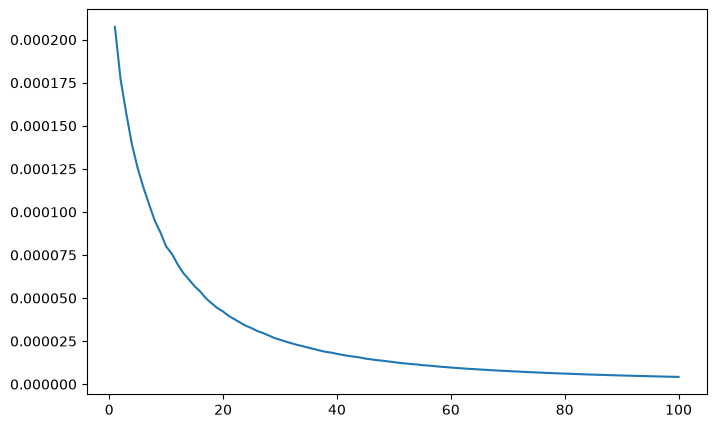

In [36]:
plt.figure(figsize=(8,5))
plt.plot(range(1,EPOCH+1),loss_history)


#### step 5. 모델 테스트하기

In [43]:
model.eval()

correct = 0
total = 0

# 테스트 데이터 전체의 예측값과 실제 정답을 저장하기 위해 리스트 생성
all_predictions = []
all_targets = []

with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)

        pred = y_hat.argmax(dim=1) #가장 높은 확률인 정답을 가져옴

        correct += (pred == y_batch).sum().item()
        total += y_batch.size(0)

        all_predictions.append(pred)
        all_targets.append(y_batch)

accuracy = correct / total * 100

y_pred = torch.cat(all_predictions)
target = torch.cat(all_targets)

print(y_pred.shape)
print(target.shape)
print(f'Accuracy : {correct} / {total} ({accuracy:.1f})')

torch.Size([37])
torch.Size([37])
Accuracy : 36 / 37 (97.3)
